In [1]:
%load_ext autoreload
%autoreload 2

import os

os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
os.environ["PYOPENGL_PLATFORM"] = "egl"
os.environ["MUJOCO_GL"] = "egl"

import functools
import gc

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from brax.training.acme import running_statistics, specs
from brax.training.agents.ppo import networks as ppo_networks

from scamper.environment.rodent import consts as rodent_consts
from scamper.environment.rodent import maintain_velocity

from scamper.agent.task_transfer.maintain_velocity.checkpoint_utils import (
    load_prior_checkpoint,
    load_task_transfer_metadata,
    load_task_transfer_brax_params,
    make_decoder_inference_fn,
    make_prior_inference_fn,
)
from scamper.agent.task_transfer.maintain_velocity.wrappers import (
    DecoderHighLevelWrapper,
    FlatObsWrapper,
    PriorDecoderHighLevelWrapper,
)
from scamper.agent.task_transfer.maintain_velocity.scratch_networks import (
    make_scratch_ppo_networks,
)

In [2]:
CKPT_BASE = "/home/mila/a/aidan.sirbu/SCAMPER/scratch/maintain_velocity_checkpoints"

CHECKPOINT_PATHS = [
    f"{CKPT_BASE}/260224_050902_050095",
    f"{CKPT_BASE}/260224_051152_844228",
    f"{CKPT_BASE}/260224_051212_790278",
    f"{CKPT_BASE}/260224_051448_856271",
    f"{CKPT_BASE}/260224_051802_732895",
    f"{CKPT_BASE}/260224_051810_581546",
    f"{CKPT_BASE}/260224_052051_490309",
    f"{CKPT_BASE}/260224_052403_540133",
    f"{CKPT_BASE}/260224_052404_878767",
    f"{CKPT_BASE}/260224_052651_836876",
    f"{CKPT_BASE}/260224_052659_700141",
    f"{CKPT_BASE}/260224_052702_802280",
    f"{CKPT_BASE}/260224_053003_851499",
    f"{CKPT_BASE}/260224_053609_837651",
    f"{CKPT_BASE}/260224_053611_454874",
    f"{CKPT_BASE}/260224_054201_922348",
    f"{CKPT_BASE}/260224_054503_743840",
    f"{CKPT_BASE}/260224_054819_055287",
    f"{CKPT_BASE}/260224_055114_219472",
    f"{CKPT_BASE}/260224_055208_922885",
    f"{CKPT_BASE}/260224_055208_938247",
    f"{CKPT_BASE}/260224_055209_002149",
    f"{CKPT_BASE}/260224_055218_633326",
    f"{CKPT_BASE}/260224_060315_506043",
    f"{CKPT_BASE}/260224_060759_119375",
    f"{CKPT_BASE}/260224_061038_000688",
    f"{CKPT_BASE}/260224_061221_416500",
    f"{CKPT_BASE}/260224_061844_393957",
    f"{CKPT_BASE}/260226_085857_764278",
    f"{CKPT_BASE}/260226_085909_402947",
    f"{CKPT_BASE}/260226_085912_284350",
    f"{CKPT_BASE}/260226_085912_962581",
    f"{CKPT_BASE}/260226_085913_693055",
    f"{CKPT_BASE}/260226_085916_024548",
    f"{CKPT_BASE}/260226_085918_040471",
    f"{CKPT_BASE}/260226_085921_796946",
    f"{CKPT_BASE}/260226_085922_283407",
    f"{CKPT_BASE}/260226_085923_102990",
    f"{CKPT_BASE}/260226_085923_120433",
    f"{CKPT_BASE}/260226_085923_279627",
    f"{CKPT_BASE}/260226_085928_397329",
    f"{CKPT_BASE}/260226_085935_990810",
    f"{CKPT_BASE}/260226_085938_586426",
    f"{CKPT_BASE}/260226_085939_630352",
    f"{CKPT_BASE}/260226_085940_932782",
    f"{CKPT_BASE}/260226_085941_965510",
    f"{CKPT_BASE}/260226_090141_370425",
    f"{CKPT_BASE}/260226_090146_759320",
    f"{CKPT_BASE}/260226_090157_067033",
    f"{CKPT_BASE}/260226_090201_316390",
    f"{CKPT_BASE}/260226_090202_664649",
    f"{CKPT_BASE}/260226_090210_978111",
    f"{CKPT_BASE}/260226_090211_049263",
    f"{CKPT_BASE}/260226_090849_117360",
    f"{CKPT_BASE}/260226_090851_633008",
    f"{CKPT_BASE}/260226_091008_466842",
    f"{CKPT_BASE}/260228_115446_896786",
    f"{CKPT_BASE}/260228_115447_566299",
    f"{CKPT_BASE}/260228_115500_929435",
    f"{CKPT_BASE}/260228_115512_882991",
    f"{CKPT_BASE}/260228_115512_893024",
    f"{CKPT_BASE}/260228_115525_043583",
    f"{CKPT_BASE}/260228_115525_352293",
    f"{CKPT_BASE}/260228_115745_522889",
    f"{CKPT_BASE}/260228_120947_605589",
    f"{CKPT_BASE}/260228_120949_207733",
    f"{CKPT_BASE}/260228_121304_648455",
    f"{CKPT_BASE}/260228_121304_661084",
    f"{CKPT_BASE}/260228_121548_335390",
    f"{CKPT_BASE}/260228_121553_030491",
    f"{CKPT_BASE}/260228_121629_226363",
    f"{CKPT_BASE}/260228_121629_318205",
    f"{CKPT_BASE}/260228_121629_410820",
    f"{CKPT_BASE}/260228_121707_498182",
    f"{CKPT_BASE}/260228_121848_320982",
    f"{CKPT_BASE}/260228_121904_541081",
    f"{CKPT_BASE}/260228_121906_581065",
    f"{CKPT_BASE}/260228_122453_972107",
    f"{CKPT_BASE}/260228_123412_394467",
    f"{CKPT_BASE}/260228_123415_281393",
    f"{CKPT_BASE}/260228_124255_399999",
    f"{CKPT_BASE}/260228_124650_681536",
    f"{CKPT_BASE}/260228_124652_539006",
    f"{CKPT_BASE}/260228_144621_293755",
]

EPISODE_LENGTH = 1000  # Rollout steps
SEED = 0  # Single rollout seed per model

In [3]:
def load_model(checkpoint_path, checkpoint_step=None):
    """Load a trained maintain_velocity model and return everything needed for rollouts.

    Returns:
        (jit_reset, jit_step, jit_inference_fn, brax_params, target_speed, config)
    """
    # Load metadata
    ckpt_info = load_task_transfer_metadata(checkpoint_path, step=checkpoint_step)
    config = ckpt_info["config"]
    ckpt_step = ckpt_info["step"]
    mode = config["mode"]
    ckpt_cfg = config["checkpoint_config"]

    target_speed = config["env"]["target_speed"]
    print(f"Loading checkpoint: {checkpoint_path}")
    print(f"  Mode: {mode}, Step: {ckpt_step}, Target speed: {target_speed}")

    # Load frozen networks from prior checkpoint
    prior_checkpoint_path = config["checkpoint"]["path"]
    prior_checkpoint_step = config["checkpoint"]["step"]
    step_prefix = "DistillNetwork" if mode == "distill" else "PriorNetwork"

    (
        encoder_params,
        prior_params,
        decoder_params,
        normalizer_params,
        _,
    ) = load_prior_checkpoint(
        prior_checkpoint_path, prior_checkpoint_step, step_prefix=step_prefix
    )

    latent_size = ckpt_cfg["network_config"]["intention_size"]
    proprio_size = ckpt_cfg["network_config"]["obs_sizes"]["proprioception"]
    action_size = ckpt_cfg["network_config"]["action_size"]

    # Create environment
    env_cfg = maintain_velocity.default_config()

    xml_variant = config["env"].get("xml_variant", "full-collisions")
    if xml_variant == "limited-collisions":
        env_cfg.walker_xml_path = rodent_consts.RODENT_XML_PATH
    elif xml_variant == "full-collisions":
        env_cfg.walker_xml_path = rodent_consts.RODENT_FULL_COLLISION_XML
    elif xml_variant == "no-tail-collisions":
        env_cfg.walker_xml_path = rodent_consts.RODENT_NO_TAIL_COLLISION_XML
    else:
        raise ValueError(f"Unknown xml_variant: {xml_variant}")

    env_cfg.mujoco_impl = config["env"].get("mujoco_impl", "jax")
    env_cfg.ctrl_dt = ckpt_cfg["env_config"]["ctrl_dt"]
    env_cfg.init_z = config["env"]["init_z"]
    env_cfg.target_speed = target_speed
    env_cfg.njmax = 1000  # Full-collisions XML can exceed default 512

    # Set actuator type: scratch mode may use PD actuators
    if mode == "scratch":
        env_cfg.torque_actuators = config["scratch"].get("torque_actuators", True)
    else:
        env_cfg.torque_actuators = True

    # Create decoder inference function and wrap environment
    decoder_fn = make_decoder_inference_fn(decoder_params, normalizer_params, ckpt_cfg)
    base_env = maintain_velocity.MaintainVelocity(config=env_cfg)

    if mode == "decoder_only":
        env = DecoderHighLevelWrapper(base_env, decoder_fn, latent_size, proprio_size)
    elif mode == "scratch":
        env = FlatObsWrapper(base_env)
    elif mode in ("prior_decoder", "distill"):
        mode_cfg = config["distill"] if mode == "distill" else config["prior_decoder"]
        prior_fn = make_prior_inference_fn(prior_params, normalizer_params, ckpt_cfg)
        env = PriorDecoderHighLevelWrapper(
            base_env,
            prior_fn,
            decoder_fn,
            latent_size,
            proprio_size,
            deterministic_prior=mode_cfg["deterministic_prior"],
            noise_logvar=mode_cfg["noise_logvar"],
        )
    else:
        raise ValueError(f"Unknown mode: {mode}")

    # JIT-compile reset and step
    jit_reset = jax.jit(env.reset)
    jit_step = jax.jit(env.step)

    # Build network and load parameters
    rng = jax.random.PRNGKey(0)
    start_state = jit_reset(rng)
    obs_size = start_state.obs.shape[-1]
    normalize = running_statistics.normalize
    policy_action_size = env.action_size

    if mode == "scratch":
        task_obs_size = obs_size - proprio_size
        decoder_hidden_layer_sizes = tuple(
            ckpt_cfg["network_config"]["decoder_layer_sizes"]
        )

        def network_factory(*args, **kwargs):
            return make_scratch_ppo_networks(
                task_obs_size=task_obs_size,
                proprio_size=proprio_size,
                action_size=action_size,
                latent_size=latent_size,
                policy_hidden_layer_sizes=tuple(config["network"]["policy_layers"]),
                decoder_hidden_layer_sizes=decoder_hidden_layer_sizes,
                value_hidden_layer_sizes=tuple(config["network"]["value_layers"]),
            )

        dummy_net = network_factory()
    else:
        network_factory = functools.partial(
            ppo_networks.make_ppo_networks,
            policy_hidden_layer_sizes=tuple(config["network"]["policy_layers"]),
            value_hidden_layer_sizes=tuple(config["network"]["value_layers"]),
        )
        dummy_net = network_factory(
            obs_size, policy_action_size, preprocess_observations_fn=normalize
        )

    key_p, key_v = jax.random.split(jax.random.PRNGKey(0))
    dummy_normalizer = running_statistics.init_state(
        specs.Array(start_state.obs.shape[-1:], jnp.dtype("float32"))
    )
    dummy_policy = dummy_net.policy_network.init(key_p)
    dummy_value = dummy_net.value_network.init(key_v)
    abstract_brax_params = (dummy_normalizer, dummy_policy, dummy_value)

    brax_params = load_task_transfer_brax_params(
        checkpoint_path, abstract_brax_params, step=ckpt_step
    )

    # Create deterministic inference function
    if mode == "scratch":
        ppo_network = network_factory()
    else:
        ppo_network = network_factory(
            obs_size, policy_action_size, preprocess_observations_fn=normalize
        )

    policy_network = ppo_network.policy_network
    parametric_action_distribution = ppo_network.parametric_action_distribution

    def inference_fn(params, observations, key_sample):
        del key_sample  # Deterministic
        param_subset = (params[0], params[1])
        logits = policy_network.apply(*param_subset, observations)
        action = parametric_action_distribution.mode(logits)
        return action, {}

    jit_inference_fn = jax.jit(inference_fn)

    print(f"  Model loaded successfully.")
    return jit_reset, jit_step, jit_inference_fn, brax_params, target_speed, config

In [4]:
def run_rollout(
    jit_reset, jit_step, jit_inference_fn, brax_params, seed, episode_length
):
    """Run a single rollout and return the mean forward speed (m/s).

    Computes actual forward speed from qvel[0] (x-component of root velocity),
    averaged over timesteps 50 to episode_length (skipping initial transient).
    """
    rng = jax.random.PRNGKey(seed)
    reset_rng, act_rng = jax.random.split(rng)

    state = jit_reset(reset_rng)
    qvel_x = []

    for _ in range(episode_length):
        _, act_rng = jax.random.split(act_rng)
        action, _ = jit_inference_fn(brax_params, state.obs, act_rng)
        state = jit_step(state, action)
        qvel_x.append(float(state.data.qvel[0]))

    # Skip first 50 steps (transient), then average
    skip = min(50, episode_length // 2)
    actual_speed = np.mean(qvel_x[skip:])
    return actual_speed

In [ ]:
# Run one rollout per model, clearing memory after each
from collections import defaultdict
from mujoco.mjx.third_party.warp._src.jax_experimental.ffi import (
    clear_jax_callable_graph_cache,
)

raw_results = []  # List of (mode, target_speed, actual_speed)

for i, ckpt_path in enumerate(CHECKPOINT_PATHS):
    print(f"[{i + 1}/{len(CHECKPOINT_PATHS)}]")
    jit_reset, jit_step, jit_inference_fn, brax_params, target_speed, config = (
        load_model(ckpt_path)
    )
    mode = config["mode"]

    actual_speed = run_rollout(
        jit_reset, jit_step, jit_inference_fn, brax_params, SEED, EPISODE_LENGTH
    )
    raw_results.append((mode, target_speed, actual_speed))
    print(f"  Target: {target_speed:.2f} m/s, Actual: {actual_speed:.3f} m/s")

    # Free model objects and clear all caches to avoid OOM
    del jit_reset, jit_step, jit_inference_fn, brax_params, config
    jax.clear_caches()
    clear_jax_callable_graph_cache()  # Free Warp CUDA graphs
    gc.collect()
    print()

# Group by (mode, target_speed)
grouped = defaultdict(lambda: defaultdict(list))
for mode, target_speed, actual_speed in raw_results:
    grouped[mode][target_speed].append(actual_speed)

print("Summary:")
for mode in sorted(grouped):
    print(f"\n  Mode: {mode}")
    for ts in sorted(grouped[mode]):
        speeds = grouped[mode][ts]
        print(
            f"    Target {ts:.2f} m/s: {np.mean(speeds):.3f} +/- {np.std(speeds):.3f} (n={len(speeds)})"
        )

[1/84]
Loading checkpoint: /home/mila/a/aidan.sirbu/SCAMPER/scratch/maintain_velocity_checkpoints/260224_050902_050095
  Mode: prior_decoder, Step: 26, Target speed: 0.3
  Model loaded successfully.
  Target: 0.30 m/s, Actual: 0.300 m/s

[2/84]
Loading checkpoint: /home/mila/a/aidan.sirbu/SCAMPER/scratch/maintain_velocity_checkpoints/260224_051152_844228
  Mode: prior_decoder, Step: 25, Target speed: 0.5
  Model loaded successfully.
  Target: 0.50 m/s, Actual: 0.486 m/s

[3/84]
Loading checkpoint: /home/mila/a/aidan.sirbu/SCAMPER/scratch/maintain_velocity_checkpoints/260224_051212_790278
  Mode: prior_decoder, Step: 25, Target speed: 0.1
  Model loaded successfully.
  Target: 0.10 m/s, Actual: 0.099 m/s

[4/84]
Loading checkpoint: /home/mila/a/aidan.sirbu/SCAMPER/scratch/maintain_velocity_checkpoints/260224_051448_856271
  Mode: prior_decoder, Step: 26, Target speed: 0.7
  Model loaded successfully.
  Target: 0.70 m/s, Actual: 0.698 m/s

[5/84]
Loading checkpoint: /home/mila/a/aidan.si

E0304 19:08:07.807780 1837507 slow_operation_alarm.cc:73] Constant folding an instruction is taking > 16s:

  %reduce_sum.91 = s32[] reduce(%constant.82, %constant.183), dimensions={0}, to_apply=%region_0.4, metadata={op_name="jit(reset)/reduce_sum" stack_frame_id=47}

This isn't necessarily a bug; constant-folding is inherently a trade-off between compilation time and speed at runtime. XLA has some guards that attempt to keep constant folding from taking too long, but fundamentally you'll always be able to come up with an input program that takes a long time.

If you'd like to file a bug, run with envvar XLA_FLAGS=--xla_dump_to=/tmp/foo and attach the results.
E0304 19:08:08.224318 1837081 slow_operation_alarm.cc:140] The operation took 16.416655194s
Constant folding an instruction is taking > 16s:

  %reduce_sum.91 = s32[] reduce(%constant.82, %constant.183), dimensions={0}, to_apply=%region_0.4, metadata={op_name="jit(reset)/reduce_sum" stack_frame_id=47}

This isn't necessarily a b

  Model loaded successfully.
  Target: 0.70 m/s, Actual: 0.702 m/s

[26/84]
Loading checkpoint: /home/mila/a/aidan.sirbu/SCAMPER/scratch/maintain_velocity_checkpoints/260224_061038_000688
  Mode: prior_decoder, Step: 25, Target speed: 1.0
  Model loaded successfully.
  Target: 1.00 m/s, Actual: 1.004 m/s

[27/84]
Loading checkpoint: /home/mila/a/aidan.sirbu/SCAMPER/scratch/maintain_velocity_checkpoints/260224_061221_416500
  Mode: prior_decoder, Step: 25, Target speed: 1.5
  Model loaded successfully.
  Target: 1.50 m/s, Actual: 1.245 m/s

[28/84]
Loading checkpoint: /home/mila/a/aidan.sirbu/SCAMPER/scratch/maintain_velocity_checkpoints/260224_061844_393957
  Mode: prior_decoder, Step: 26, Target speed: 2.0
  Model loaded successfully.
  Target: 2.00 m/s, Actual: 1.294 m/s

[29/84]
Loading checkpoint: /home/mila/a/aidan.sirbu/SCAMPER/scratch/maintain_velocity_checkpoints/260226_085857_764278
  Mode: decoder_only, Step: 26, Target speed: 0.3
  Model loaded successfully.
  Target: 0.30 m

In [11]:
# Save rollout results to CSV for reuse without re-running rollouts
import pandas as pd
from pathlib import Path

save_dir = Path("/home/mila/a/aidan.sirbu/SCAMPER/data/maintain_velocity_analysis")
save_dir.mkdir(parents=True, exist_ok=True)

df_results = pd.DataFrame(raw_results, columns=["mode", "target_speed", "actual_speed"])
csv_path = save_dir / "maintain_velocity_tracking_rollouts.csv"
df_results.to_csv(csv_path, index=False)
print(f"Saved {len(df_results)} rollout results to {csv_path}")
df_results.head()

Saved 112 rollout results to /home/mila/a/aidan.sirbu/SCAMPER/data/maintain_velocity_analysis/maintain_velocity_tracking_rollouts.csv


,mode,target_speed,actual_speed
0,prior_decoder,0.3,0.300194
1,prior_decoder,0.5,0.486483
2,prior_decoder,0.1,0.099363
3,prior_decoder,0.7,0.698364
4,prior_decoder,1.5,1.245570


In [5]:
# Load rollout results from CSV (skip cells 0-5 if data already saved)
import pandas as pd
import numpy as np
from pathlib import Path
from collections import defaultdict

csv_path = Path(
    "/home/mila/a/aidan.sirbu/SCAMPER/data/maintain_velocity_analysis/maintain_velocity_tracking_rollouts.csv"
)
df_loaded = pd.read_csv(csv_path)

raw_results = list(df_loaded.itertuples(index=False, name=None))

grouped = defaultdict(lambda: defaultdict(list))
for mode, target_speed, actual_speed in raw_results:
    grouped[mode][target_speed].append(actual_speed)

print(f"Loaded {len(raw_results)} rollout results from {csv_path}")
print(f"Modes: {sorted(grouped.keys())}")
print(f"Speeds per mode: {dict({m: sorted(grouped[m].keys()) for m in grouped})}")

Loaded 112 rollout results from /home/mila/a/aidan.sirbu/SCAMPER/data/maintain_velocity_analysis/maintain_velocity_tracking_rollouts.csv
Modes: ['decoder_only', 'distill', 'prior_decoder', 'scratch']
Speeds per mode: {'prior_decoder': [0.1, 0.3, 0.5, 0.7, 1.0, 1.5, 2.0], 'decoder_only': [0.1, 0.3, 0.5, 0.7, 1.0, 1.5, 2.0], 'scratch': [0.1, 0.3, 0.5, 0.7, 1.0, 1.5, 2.0], 'distill': [0.1, 0.3, 0.5, 0.7, 1.0, 1.5, 2.0]}


In [6]:
# (Optional) Run rollouts for new checkpoints and amend the loaded data
# Set NEW_CHECKPOINT_PATHS to a non-empty list to run, or leave empty to skip.
from mujoco.mjx.third_party.warp._src.jax_experimental.ffi import (
    clear_jax_callable_graph_cache,
)

NEW_CHECKPOINT_PATHS = [
    f"{CKPT_BASE}/260403_014136_888926",
    f"{CKPT_BASE}/260403_015355_799301",
    f"{CKPT_BASE}/260403_015403_017303",
    f"{CKPT_BASE}/260403_020312_245983",
    f"{CKPT_BASE}/260403_021525_967470",
    f"{CKPT_BASE}/260403_022124_396297",
    f"{CKPT_BASE}/260403_022132_285724",
    f"{CKPT_BASE}/260403_022137_729032",
    f"{CKPT_BASE}/260403_024200_583261",
    f"{CKPT_BASE}/260403_054638_949446",
    f"{CKPT_BASE}/260403_054638_957503",
    f"{CKPT_BASE}/260403_054651_115813",
    f"{CKPT_BASE}/260403_054651_738260",
    f"{CKPT_BASE}/260403_054931_313376",
    f"{CKPT_BASE}/260403_054936_177691",
    f"{CKPT_BASE}/260403_054936_245874",
    f"{CKPT_BASE}/260403_054959_321773",
    f"{CKPT_BASE}/260403_054959_329218",
    f"{CKPT_BASE}/260403_055004_184735",
    f"{CKPT_BASE}/260403_055140_554296",
    f"{CKPT_BASE}/260403_055154_760570",
    f"{CKPT_BASE}/260403_055504_304389",
    f"{CKPT_BASE}/260403_055856_753857",
    f"{CKPT_BASE}/260403_055900_737099",
    f"{CKPT_BASE}/260403_060356_897442",
    f"{CKPT_BASE}/260403_060357_827877",
    f"{CKPT_BASE}/260403_062220_845614",
    f"{CKPT_BASE}/260403_062510_787957",
]

EPISODE_LENGTH = 1000
SEED = 0

if NEW_CHECKPOINT_PATHS:
    new_results = []
    for i, ckpt_path in enumerate(NEW_CHECKPOINT_PATHS):
        print(f"[{i + 1}/{len(NEW_CHECKPOINT_PATHS)}]")
        jit_reset, jit_step, jit_inference_fn, brax_params, target_speed, config = (
            load_model(ckpt_path)
        )
        mode = config["mode"]

        actual_speed = run_rollout(
            jit_reset, jit_step, jit_inference_fn, brax_params, SEED, EPISODE_LENGTH
        )
        new_results.append((mode, target_speed, actual_speed))
        print(f"  Target: {target_speed:.2f} m/s, Actual: {actual_speed:.3f} m/s")

        del jit_reset, jit_step, jit_inference_fn, brax_params, config
        jax.clear_caches()
        clear_jax_callable_graph_cache()
        gc.collect()
        print()

    # Amend raw_results and grouped
    raw_results.extend(new_results)
    for mode, target_speed, actual_speed in new_results:
        grouped[mode][target_speed].append(actual_speed)

    # Append to CSV
    df_new = pd.DataFrame(new_results, columns=["mode", "target_speed", "actual_speed"])
    df_new.to_csv(csv_path, mode="a", header=False, index=False)
    print(f"Appended {len(new_results)} new results to {csv_path}")
    print(f"Total results: {len(raw_results)}")
else:
    print("No new checkpoints to run.")

[1/28]
Loading checkpoint: /home/mila/a/aidan.sirbu/SCAMPER/scratch/maintain_velocity_checkpoints/260403_014136_888926
  Mode: distill, Step: 25, Target speed: 0.1
Warp 1.11.1 initialized:
   CUDA Toolkit 12.9, Driver 13.0
   Devices:
     "cpu"      : "x86_64"
     "cuda:0"   : "Quadro RTX 8000" (44 GiB, sm_75, mempool enabled)
   Kernel cache:
     /home/mila/a/aidan.sirbu/.cache/warp/1.11.1
Warp DeprecationWarning: The symbol `warp.types.warp_type_to_np_dtype` will soon be removed from the public API. It can still be accessed from `warp._src.types.warp_type_to_np_dtype` but might be changed or removed without notice.


E0405 11:54:44.089711  561190 slow_operation_alarm.cc:73] Constant folding an instruction is taking > 1s:

  %reduce_sum.91 = s32[] reduce(%constant.76, %constant.183), dimensions={0}, to_apply=%region_0.4, metadata={op_name="jit(reset)/reduce_sum" stack_frame_id=10}

This isn't necessarily a bug; constant-folding is inherently a trade-off between compilation time and speed at runtime. XLA has some guards that attempt to keep constant folding from taking too long, but fundamentally you'll always be able to come up with an input program that takes a long time.

If you'd like to file a bug, run with envvar XLA_FLAGS=--xla_dump_to=/tmp/foo and attach the results.
E0405 11:54:57.293240  560321 slow_operation_alarm.cc:140] The operation took 14.203664188s
Constant folding an instruction is taking > 1s:

  %reduce_sum.91 = s32[] reduce(%constant.76, %constant.183), dimensions={0}, to_apply=%region_0.4, metadata={op_name="jit(reset)/reduce_sum" stack_frame_id=10}

This isn't necessarily a bug

  Model loaded successfully.
Module mujoco.mjx.warp.ffi edde159 load on device 'cuda:0' took 2.66 ms  (cached)
Module mujoco.mjx.third_party.mujoco_warp._src.smooth 238b9c7 load on device 'cuda:0' took 9.18 ms  (cached)
Module mujoco.mjx.third_party.mujoco_warp._src.collision_driver de6dc98 load on device 'cuda:0' took 2.31 ms  (cached)
Module _nxn_broadphase__locals__kernel_937dc256 937dc25 load on device 'cuda:0' took 2.10 ms  (cached)
Module _primitive_narrowphase__locals__primitive_narrowphase_43147716 ccfa123 load on device 'cuda:0' took 2.85 ms  (cached)
Module mujoco.mjx.third_party.mujoco_warp._src.constraint 1a0b074 load on device 'cuda:0' took 3.98 ms  (cached)
Module mujoco.mjx.third_party.mujoco_warp._src.forward f17e7b2 load on device 'cuda:0' took 2.83 ms  (cached)
Module _tendon_velocity__locals__tendon_velocity_37e20a74 33946cf load on device 'cuda:0' took 2.12 ms  (cached)
Module mujoco.mjx.third_party.mujoco_warp._src.passive 6c43d71 load on device 'cuda:0' took 2.50 

E0405 11:55:58.245980  561190 slow_operation_alarm.cc:73] Constant folding an instruction is taking > 2s:

  %reduce_sum.91 = s32[] reduce(%constant.76, %constant.183), dimensions={0}, to_apply=%region_0.4, metadata={op_name="jit(reset)/reduce_sum" stack_frame_id=10}

This isn't necessarily a bug; constant-folding is inherently a trade-off between compilation time and speed at runtime. XLA has some guards that attempt to keep constant folding from taking too long, but fundamentally you'll always be able to come up with an input program that takes a long time.

If you'd like to file a bug, run with envvar XLA_FLAGS=--xla_dump_to=/tmp/foo and attach the results.
E0405 11:56:10.502141  560321 slow_operation_alarm.cc:140] The operation took 14.256275351s
Constant folding an instruction is taking > 2s:

  %reduce_sum.91 = s32[] reduce(%constant.76, %constant.183), dimensions={0}, to_apply=%region_0.4, metadata={op_name="jit(reset)/reduce_sum" stack_frame_id=10}

This isn't necessarily a bug

  Model loaded successfully.
  Target: 0.50 m/s, Actual: 0.502 m/s

[3/28]
Loading checkpoint: /home/mila/a/aidan.sirbu/SCAMPER/scratch/maintain_velocity_checkpoints/260403_015403_017303
  Mode: distill, Step: 26, Target speed: 0.3


E0405 11:57:10.399666  561190 slow_operation_alarm.cc:73] Constant folding an instruction is taking > 4s:

  %reduce_sum.91 = s32[] reduce(%constant.76, %constant.183), dimensions={0}, to_apply=%region_0.4, metadata={op_name="jit(reset)/reduce_sum" stack_frame_id=10}

This isn't necessarily a bug; constant-folding is inherently a trade-off between compilation time and speed at runtime. XLA has some guards that attempt to keep constant folding from taking too long, but fundamentally you'll always be able to come up with an input program that takes a long time.

If you'd like to file a bug, run with envvar XLA_FLAGS=--xla_dump_to=/tmp/foo and attach the results.
E0405 11:57:20.621900  560321 slow_operation_alarm.cc:140] The operation took 14.22232452s
Constant folding an instruction is taking > 4s:

  %reduce_sum.91 = s32[] reduce(%constant.76, %constant.183), dimensions={0}, to_apply=%region_0.4, metadata={op_name="jit(reset)/reduce_sum" stack_frame_id=10}

This isn't necessarily a bug;

  Model loaded successfully.
  Target: 0.30 m/s, Actual: 0.301 m/s

[4/28]
Loading checkpoint: /home/mila/a/aidan.sirbu/SCAMPER/scratch/maintain_velocity_checkpoints/260403_020312_245983
  Mode: distill, Step: 26, Target speed: 0.7


E0405 11:58:22.222389  561190 slow_operation_alarm.cc:73] Constant folding an instruction is taking > 8s:

  %reduce_sum.91 = s32[] reduce(%constant.76, %constant.183), dimensions={0}, to_apply=%region_0.4, metadata={op_name="jit(reset)/reduce_sum" stack_frame_id=10}

This isn't necessarily a bug; constant-folding is inherently a trade-off between compilation time and speed at runtime. XLA has some guards that attempt to keep constant folding from taking too long, but fundamentally you'll always be able to come up with an input program that takes a long time.

If you'd like to file a bug, run with envvar XLA_FLAGS=--xla_dump_to=/tmp/foo and attach the results.
E0405 11:58:28.392487  560321 slow_operation_alarm.cc:140] The operation took 14.170220575s
Constant folding an instruction is taking > 8s:

  %reduce_sum.91 = s32[] reduce(%constant.76, %constant.183), dimensions={0}, to_apply=%region_0.4, metadata={op_name="jit(reset)/reduce_sum" stack_frame_id=10}

This isn't necessarily a bug

  Model loaded successfully.
  Target: 0.70 m/s, Actual: 0.702 m/s

[5/28]
Loading checkpoint: /home/mila/a/aidan.sirbu/SCAMPER/scratch/maintain_velocity_checkpoints/260403_021525_967470
  Mode: distill, Step: 26, Target speed: 1.0
  Model loaded successfully.
  Target: 1.00 m/s, Actual: 1.004 m/s

[6/28]
Loading checkpoint: /home/mila/a/aidan.sirbu/SCAMPER/scratch/maintain_velocity_checkpoints/260403_022124_396297
  Mode: distill, Step: 26, Target speed: 0.1
  Model loaded successfully.
  Target: 0.10 m/s, Actual: 0.101 m/s

[7/28]
Loading checkpoint: /home/mila/a/aidan.sirbu/SCAMPER/scratch/maintain_velocity_checkpoints/260403_022132_285724
  Mode: distill, Step: 26, Target speed: 2.0
  Model loaded successfully.
  Target: 2.00 m/s, Actual: 2.007 m/s

[8/28]
Loading checkpoint: /home/mila/a/aidan.sirbu/SCAMPER/scratch/maintain_velocity_checkpoints/260403_022137_729032
  Mode: distill, Step: 26, Target speed: 1.5
  Model loaded successfully.
  Target: 1.50 m/s, Actual: 1.510 m/s

[9/2

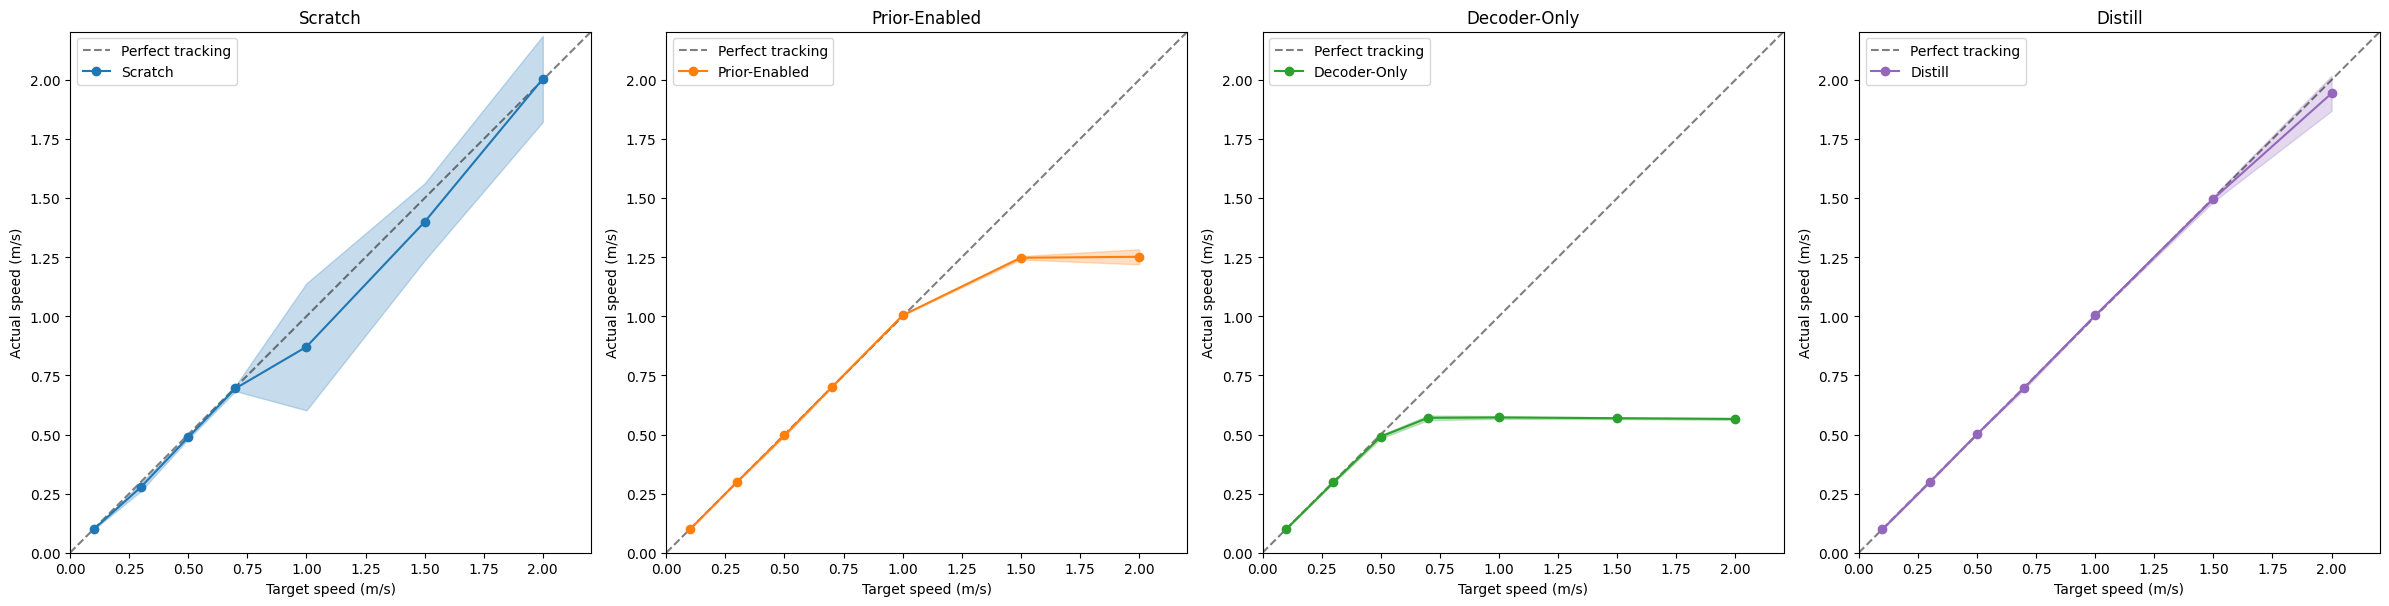

In [6]:
# Plot target vs actual speed, one subplot per training mode
MODE_LABELS = {
    "scratch": "Scratch",
    "prior_decoder": "Prior-Enabled",
    "decoder_only": "Decoder-Only",
    "distill": "Distill",
}
MODE_COLORS = {
    "scratch": "tab:blue",
    "prior_decoder": "tab:orange",
    "decoder_only": "tab:green",
    "distill": "tab:purple",
}
MODE_ORDER = ["scratch", "prior_decoder", "decoder_only", "distill"]

# Only plot modes that have data
modes_with_data = [m for m in MODE_ORDER if m in grouped]

fig, axes = plt.subplots(1, len(modes_with_data), figsize=(6 * len(modes_with_data), 6))
if len(modes_with_data) == 1:
    axes = [axes]

# Compute global axis range across all modes
all_targets = []
all_means = []
for mode in modes_with_data:
    for ts in grouped[mode]:
        all_targets.append(ts)
        all_means.append(np.mean(grouped[mode][ts]))
speed_range = [0, max(max(all_targets), max(all_means)) * 1.1]

for ax, mode in zip(axes, modes_with_data):
    target_speeds = np.array(sorted(grouped[mode].keys()))
    mean_speeds = np.array([np.mean(grouped[mode][ts]) for ts in target_speeds])
    std_speeds = np.array([np.std(grouped[mode][ts]) for ts in target_speeds])
    color = MODE_COLORS[mode]

    ax.plot(speed_range, speed_range, "k--", alpha=0.5, label="Perfect tracking")
    ax.plot(target_speeds, mean_speeds, "o-", color=color, label=MODE_LABELS[mode])
    ax.fill_between(
        target_speeds,
        mean_speeds - std_speeds,
        mean_speeds + std_speeds,
        alpha=0.25,
        color=color,
    )

    ax.set_xlabel("Target speed (m/s)")
    ax.set_ylabel("Actual speed (m/s)")
    ax.set_title(MODE_LABELS[mode])
    ax.legend()
    ax.set_aspect("equal")
    ax.set_xlim(speed_range)
    ax.set_ylim(speed_range)

plt.tight_layout()
plt.show()

Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/rl_performance/maintain_velocity_tracking.[pdf|svg|png]


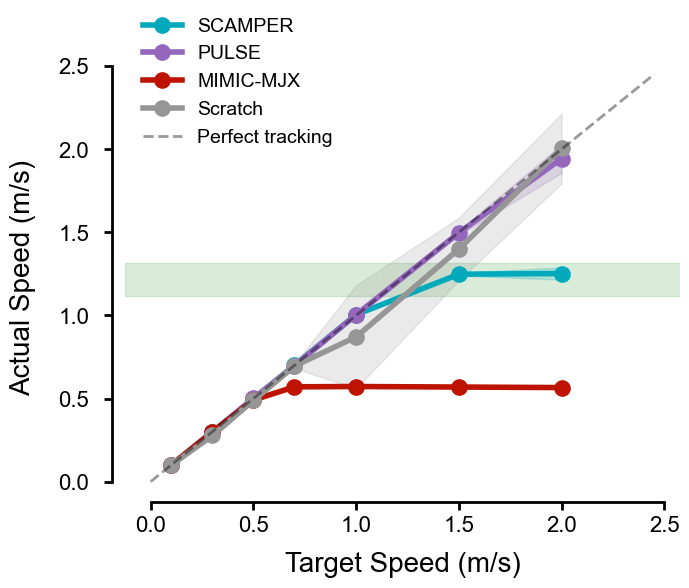

In [7]:
import matplotlib as mpl

mpl.rcParams["font.family"] = "sans-serif"
mpl.rcParams["font.sans-serif"] = ["Arial"]
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42

import seaborn as sns

# Build a long-format DataFrame from grouped results
rows = []
for mode, target_speed, actual_speed in raw_results:
    rows.append({"speed": target_speed, "mode": mode, "actual_speed": actual_speed})

import pandas as pd

df = pd.DataFrame(rows)

# Map mode names to legend labels
mode_labels = {
    "prior_decoder": "SCAMPER",
    "decoder_only": "MIMIC-MJX",
    "scratch": "Scratch",
    "distill": "PULSE",
}
df["Training Mode"] = df["mode"].map(mode_labels)

# Define colors for each training mode
palette = {
    "SCAMPER": tuple(c / 255 for c in (0, 170, 188)),
    "MIMIC-MJX": tuple(c / 255 for c in (189, 19, 0)),
    "Scratch": tuple(c / 255 for c in (150, 150, 150)),
    "PULSE": (148 / 255, 103 / 255, 189 / 255),
}

hue_order = ["SCAMPER", "PULSE", "MIMIC-MJX", "Scratch"]

save_dir = Path("../../notebooks/plots/rl_performance")
save_name = "maintain_velocity_tracking"

fig, ax = plt.subplots(figsize=(7, 6))

sns.lineplot(
    data=df,
    x="speed",
    y="actual_speed",
    hue="Training Mode",
    hue_order=hue_order,
    palette=palette,
    errorbar="sd",
    marker="o",
    markersize=12,
    markeredgewidth=0,
    linewidth=4,
    ax=ax,
)

# Shaded region between 1.117 and 1.317 m/s actual speed
ax.axhspan(1.117, 1.317, color="green", alpha=0.15, zorder=0)

# y=x reference line
max_speed = max(df["speed"].max(), df["actual_speed"].max()) * 1.1
ax.plot(
    [0, max_speed],
    [0, max_speed],
    "k--",
    alpha=0.4,
    linewidth=2,
    label="Perfect tracking",
)

ax.set_xlabel("Target Speed (m/s)", fontsize=20, labelpad=12)
ax.set_ylabel("Actual Speed (m/s)", fontsize=20, labelpad=16)
ax.tick_params(labelsize=16, width=2, length=6)
ax.tick_params(axis="y", pad=10)

# Remove top and right spines
sns.despine(ax=ax)

# Trim spines to data range
xticks = ax.get_xticks()
yticks = ax.get_yticks()
xlim = ax.get_xlim()
ylim = ax.get_ylim()
xticks = [t for t in xticks if xlim[0] <= t <= xlim[1]]
yticks = [t for t in yticks if ylim[0] <= t <= ylim[1]]

ax.spines["bottom"].set_bounds(xticks[0], xticks[-1])
ax.spines["left"].set_bounds(yticks[0], yticks[-1])

# Shift y-axis spine to the left
ax.spines["left"].set_position(("outward", 10))

# Thicken remaining spines
for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(2)

# Style legend - top right, shifted upwards
ax.legend(fontsize=14, frameon=False, loc="upper left", bbox_to_anchor=(0.0, 1.12))

plt.tight_layout()

# Save
from pathlib import Path

save_dir = Path("/home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/rl_performance")
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"{save_name}.pdf", bbox_inches="tight")
fig.savefig(save_dir / f"{save_name}.svg", bbox_inches="tight")
fig.savefig(save_dir / f"{save_name}.png", bbox_inches="tight")
print(f"Saved to {save_dir / save_name}.[pdf|svg|png]")

plt.show()

In [8]:
# Load movement bout data
bout_df = pd.read_csv(
    "/home/mila/a/aidan.sirbu/SCAMPER/data/maintain_velocity_analysis/movement_bout_data.csv"
)

bout_peak_speeds = bout_df["peak_speed_ms"].values
bout_mean_speed = np.mean(bout_peak_speeds)
bout_max_speed = np.max(bout_peak_speeds)
bout_min_speed = np.min(bout_peak_speeds)

print(f"Movement bout peak speeds (n={len(bout_peak_speeds)}):")
print(f"  Mean: {bout_mean_speed:.3f} m/s")
print(f"  Max:  {bout_max_speed:.3f} m/s")
print(f"  Min:  {bout_min_speed:.3f} m/s")

Movement bout peak speeds (n=554):
  Mean: 0.531 m/s
  Max:  1.299 m/s
  Min:  0.171 m/s


Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/maintain_velocity_tracking.[pdf|svg|png]


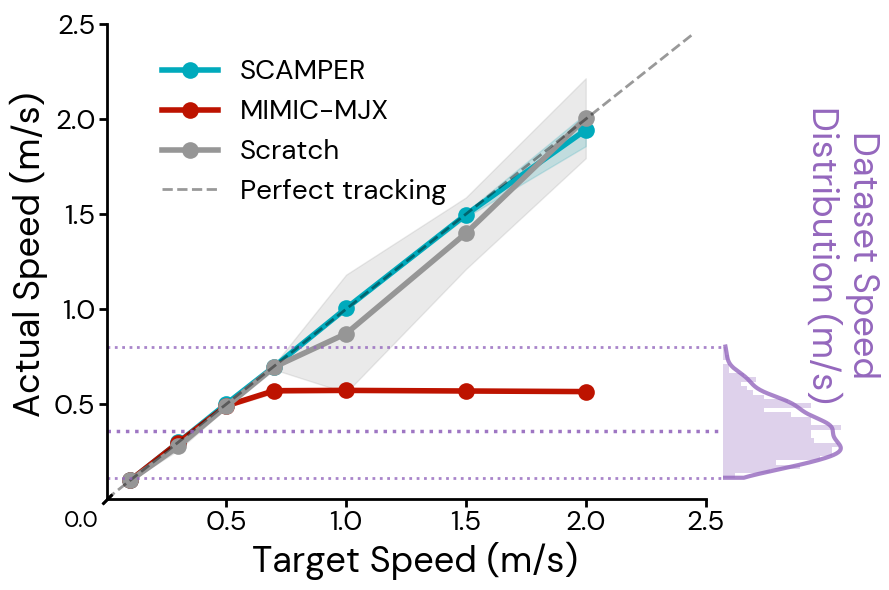

In [15]:
import matplotlib

matplotlib.rcParams["font.family"] = "DM Sans"

# Replot with movement bout reference lines + marginal distribution
from matplotlib.gridspec import GridSpec
from scipy.stats import gaussian_kde

save_name_bout = "maintain_velocity_tracking"

# Override labels: remove old SCAMPER, rename PULSE -> SCAMPER with old SCAMPER's color
df_bout = df[df["Training Mode"] != "SCAMPER"].copy()
df_bout["Training Mode"] = df_bout["Training Mode"].replace({"PULSE": "SCAMPER"})

palette_bout = {
    "SCAMPER": tuple(c / 255 for c in (0, 170, 188)),  # old SCAMPER teal color
    "MIMIC-MJX": tuple(c / 255 for c in (189, 19, 0)),
    "Scratch": tuple(c / 255 for c in (150, 150, 150)),
}
hue_order_bout = [
    m
    for m in ["SCAMPER", "MIMIC-MJX", "Scratch"]
    if m in df_bout["Training Mode"].values
]

# Use mean peak window speed instead of peak speed
bout_mean_window_speeds = bout_df["mean_peak_window_speed_ms"].values
bout_mw_mean = np.mean(bout_mean_window_speeds)
bout_mw_max = np.max(bout_mean_window_speeds)
bout_mw_min = np.min(bout_mean_window_speeds)

fig = plt.figure(figsize=(9, 6))
gs = GridSpec(1, 2, width_ratios=[5, 1], wspace=0)
ax_main = fig.add_subplot(gs[0])
ax_dist = fig.add_subplot(gs[1], sharey=ax_main)

# --- Main plot ---
sns.lineplot(
    data=df_bout,
    x="speed",
    y="actual_speed",
    hue="Training Mode",
    hue_order=hue_order_bout,
    palette=palette_bout,
    errorbar="sd",
    marker="o",
    markersize=12,
    markeredgewidth=0,
    linewidth=4,
    ax=ax_main,
)

# y=x reference line
max_speed = max(df_bout["speed"].max(), df_bout["actual_speed"].max()) * 1.1
ax_main.plot(
    [0, max_speed],
    [0, max_speed],
    "k--",
    alpha=0.4,
    linewidth=2,
    label="Perfect tracking",
)

# Mean peak window speed reference lines: mean, max, min
bout_color = "tab:purple"
ax_main.axhline(bout_mw_mean, color=bout_color, linestyle=":", linewidth=2.5, alpha=0.9)
ax_main.axhline(bout_mw_max, color=bout_color, linestyle=":", linewidth=2, alpha=0.8)
ax_main.axhline(bout_mw_min, color=bout_color, linestyle=":", linewidth=2, alpha=0.8)

ax_main.set_xlabel("Target Speed (m/s)", fontsize=26, labelpad=4)
ax_main.set_ylabel("Actual Speed (m/s)", fontsize=26, labelpad=4)
ax_main.tick_params(labelsize=20, width=2, length=6)
ax_main.tick_params(axis="y", pad=2)
ax_main.tick_params(axis="x", pad=2)

# Force axes to start at 0 so spines connect at the origin
ax_main.set_xlim(left=0)
ax_main.set_ylim(bottom=0)

sns.despine(ax=ax_main)

xticks = ax_main.get_xticks()
yticks = ax_main.get_yticks()
xlim = ax_main.get_xlim()
ylim = ax_main.get_ylim()
xticks = [t for t in xticks if xlim[0] <= t <= xlim[1]]
yticks = [t for t in yticks if ylim[0] <= t <= ylim[1]]

ax_main.spines["bottom"].set_bounds(0, xticks[-1])
ax_main.spines["left"].set_bounds(0, yticks[-1])

# Remove 0 from both axes' ticks
ax_main.set_xticks([t for t in xticks if t != 0])
ax_main.set_yticks([t for t in yticks if t != 0])

# Draw a diagonal tick at the origin corner
ax_main.plot(
    [0, 0],
    [0, 0],
    marker=(2, 0, -45),
    markersize=10,
    markeredgewidth=2,
    color="black",
    clip_on=False,
    transform=ax_main.transData,
)
# Add "0.0" label below-left of the origin
ax_main.annotate(
    "0.0",
    xy=(0, 0),
    xycoords="data",
    xytext=(-18, -8),
    textcoords="offset points",
    fontsize=16,
    ha="center",
    va="top",
    clip_on=False,
)

for spine in ["left", "bottom"]:
    ax_main.spines[spine].set_linewidth(2)

ax_main.legend(
    fontsize=20, frameon=False, loc="upper left", bbox_to_anchor=(0.05, 0.95)
)

# --- Marginal histogram + KDE of mean peak window speeds ---
ax_dist.hist(
    bout_mean_window_speeds,
    bins=30,
    orientation="horizontal",
    color=bout_color,
    alpha=0.3,
    edgecolor="none",
)

# KDE overlay scaled to match histogram, with vertical drop to 0 at min
kde = gaussian_kde(bout_mean_window_speeds)
y_grid = np.linspace(bout_mean_window_speeds.min(), bout_mean_window_speeds.max(), 300)
kde_vals = kde(y_grid)
hist_counts, _ = np.histogram(bout_mean_window_speeds, bins=30)
kde_scale = hist_counts.max() / kde_vals.max()
kde_scaled = kde_vals * kde_scale

# Append a point at (0, min) so the line drops straight down
y_plot = np.concatenate([[bout_mean_window_speeds.min()], y_grid])
x_plot = np.concatenate([[0], kde_scaled])
ax_dist.plot(x_plot, y_plot, color=bout_color, linewidth=3, alpha=0.8)

ax_dist.tick_params(labelbottom=False, labelleft=False, length=0)
sns.despine(ax=ax_dist, left=True, bottom=True)

# Vertical label on the right side of the distribution panel
ax_dist.set_ylabel(
    "Dataset Speed\nDistribution (m/s)",
    fontsize=26,
    color=bout_color,
    rotation=270,
    labelpad=24,
)
ax_dist.yaxis.set_label_position("right")

plt.tight_layout()

# Save
save_dir = Path(
    "/home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots"
)
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"{save_name_bout}.pdf", bbox_inches="tight")
fig.savefig(save_dir / f"{save_name_bout}.svg", bbox_inches="tight")
fig.savefig(save_dir / f"{save_name_bout}.png", bbox_inches="tight")
print(f"Saved to {save_dir / save_name_bout}.[pdf|svg|png]")

plt.show()

Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/rl_performance/maintain_velocity_tracking_fig5_style.[pdf|svg|png]
Mean peak window speed: 0.360 +/- 0.135 m/s
  -2std: 0.090, +2std: 0.629


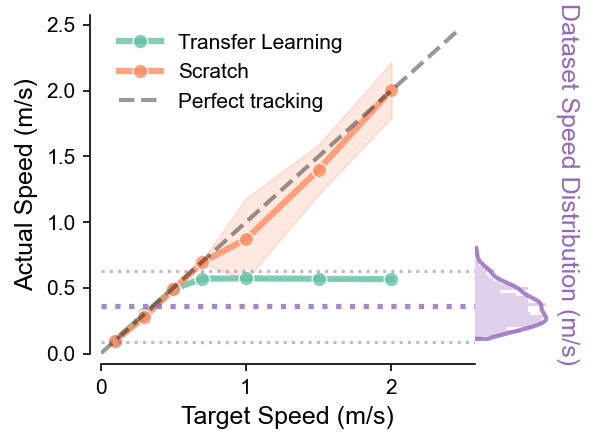

In [10]:
# Line plot in fig5 style
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.gridspec import GridSpec
from scipy.stats import gaussian_kde

mpl.rcParams["figure.facecolor"] = "w"
mpl.rcParams["figure.dpi"] = 150
mpl.rcParams["savefig.dpi"] = 600
mpl.rcParams["savefig.transparent"] = True
mpl.rcParams["font.size"] = 8
mpl.rcParams["font.family"] = "sans-serif"
mpl.rcParams["font.sans-serif"] = ["Arial"]
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42
mpl.style.use("seaborn-v0_8-deep")

# Filter out prior_decoder and distill, rename Decoder-Only -> Transfer Learning
df_fig5 = df[~df["mode"].isin(["prior_decoder", "distill"])].copy()
df_fig5["Training Mode"] = df_fig5["mode"].map(
    {
        "decoder_only": "Transfer Learning",
        "scratch": "Scratch",
    }
)

set2 = sns.color_palette("Set2")
palette = {
    "Transfer Learning": set2[0],
    "Scratch": set2[1],
}
hue_order = ["Transfer Learning", "Scratch"]

# Dataset speed distribution data
bout_mean_window_speeds = bout_df["mean_peak_window_speed_ms"].values
mpw_mean = np.mean(bout_mean_window_speeds)
mpw_std = np.std(bout_mean_window_speeds)
bout_color = "tab:purple"

fig = plt.figure(figsize=(4, 3))
gs = GridSpec(1, 2, width_ratios=[5, 1], wspace=0)
ax = fig.add_subplot(gs[0])
ax_dist = fig.add_subplot(gs[1], sharey=ax)

# --- Main plot ---
sns.lineplot(
    data=df_fig5,
    x="speed",
    y="actual_speed",
    hue="Training Mode",
    hue_order=hue_order,
    palette=palette,
    errorbar="sd",
    marker="o",
    markersize=7,
    linewidth=3,
    alpha=0.8,
    ax=ax,
)

# y=x reference line
max_speed = max(df_fig5["speed"].max(), df_fig5["actual_speed"].max()) * 1.1
ax.plot(
    [0, max_speed],
    [0, max_speed],
    "k--",
    alpha=0.4,
    linewidth=2,
    label="Perfect tracking",
)

# Mean peak window speed reference lines (mean +/- 2 std)
ax.axhline(
    mpw_mean,
    color=bout_color,
    linestyle=":",
    linewidth=2.5,
    alpha=0.8,
)
ax.axhline(
    mpw_mean + 2 * mpw_std, color=bout_color, linestyle=":", linewidth=1.5, alpha=0.5
)
ax.axhline(
    mpw_mean - 2 * mpw_std, color=bout_color, linestyle=":", linewidth=1.5, alpha=0.5
)

ax.set_xlabel("Target Speed (m/s)", fontsize=12)
ax.set_ylabel("Actual Speed (m/s)", fontsize=12)

# Force axes to start at 0 so spines connect at the origin
ax.set_xlim(left=0)
ax.set_ylim(bottom=0)

ax.tick_params(axis="both", labelsize=10)

sns.despine(ax=ax)
ax.spines["left"].set_position(("outward", 5))
ax.spines["bottom"].set_position(("outward", 5))

ax.legend(
    fontsize=10,
    frameon=False,
    loc="upper left",
)

# --- Marginal histogram + KDE of dataset speeds ---
ax_dist.hist(
    bout_mean_window_speeds,
    bins=30,
    orientation="horizontal",
    color=bout_color,
    alpha=0.3,
    edgecolor="none",
)

# KDE overlay scaled to match histogram, with vertical drop to 0 at min
kde = gaussian_kde(bout_mean_window_speeds)
y_grid = np.linspace(bout_mean_window_speeds.min(), bout_mean_window_speeds.max(), 300)
kde_vals = kde(y_grid)
hist_counts, _ = np.histogram(bout_mean_window_speeds, bins=30)
kde_scale = hist_counts.max() / kde_vals.max()
kde_scaled = kde_vals * kde_scale

# Append a point at (0, min) so the line drops straight down
y_plot = np.concatenate([[bout_mean_window_speeds.min()], y_grid])
x_plot = np.concatenate([[0], kde_scaled])
ax_dist.plot(x_plot, y_plot, color=bout_color, linewidth=2, alpha=0.8)

ax_dist.tick_params(labelbottom=False, labelleft=False, length=0)
sns.despine(ax=ax_dist, left=True, bottom=True)

# Vertical label on the right side of the distribution panel
ax_dist.set_ylabel(
    "Dataset Speed Distribution (m/s)",
    fontsize=12,
    color=bout_color,
    rotation=270,
    labelpad=14,
)
ax_dist.yaxis.set_label_position("right")

plt.tight_layout()

save_dir = Path("/home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/rl_performance")
save_dir.mkdir(parents=True, exist_ok=True)
save_name = "maintain_velocity_tracking_fig5_style"
fig.savefig(save_dir / f"{save_name}.pdf", bbox_inches="tight")
fig.savefig(save_dir / f"{save_name}.svg", bbox_inches="tight")
fig.savefig(save_dir / f"{save_name}.png", bbox_inches="tight")
print(f"Saved to {save_dir / save_name}.[pdf|svg|png]")
print(f"Mean peak window speed: {mpw_mean:.3f} +/- {mpw_std:.3f} m/s")
print(f"  -2std: {mpw_mean - 2*mpw_std:.3f}, +2std: {mpw_mean + 2*mpw_std:.3f}")

plt.show()